# 04. Hypothesis summary across stakeholder groups

**Business question.** What should the brand team test next, for whom, and in what order?

The framework turns each quadrant placement into a structured hypothesis with the same fields every time: group,
driver, quadrant, evidence (importance r and performance), a falsifiable statement, a proposed test and an action. All
priority fixes and strengths become hypotheses; the two best-rated "Maintain" drivers become reallocation hypotheses
and the top "Low priority" driver a monitor item. Cross-group hypotheses are added where a driver lands in the same
actionable quadrant for two or more groups. Borderline calls from the bootstrap in notebook 03 are flagged.

In [1]:
import os
# Single-threaded BLAS: avoids thread oversubscription and keeps timings reproducible on shared machines.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from plotting import apply_style, PALETTE
from generate_data import ATTRIBUTES, OUTCOME, OUTCOME_LABELS
apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)

RAW = Path("../data/raw/stakeholder_survey.csv")
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
FIGS = Path("../reports/figures"); FIGS.mkdir(parents=True, exist_ok=True)
DRIVERS = list(ATTRIBUTES)
GROUPS = ["Physicians", "Pharmacists", "Patients", "Payers"]

from kda import run_kda, cross_group_hypotheses

In [2]:
df = pd.read_csv(RAW)
results = run_kda(df, "stakeholder_group", DRIVERS, OUTCOME, OUTCOME_LABELS, ATTRIBUTES)
robust = pd.read_csv(PROCESSED / "robustness_checks.csv")[["group", "driver", "stable", "rank_rw"]]

hyp = pd.concat([results[g].hypotheses for g in GROUPS], ignore_index=True)
hyp = hyp.merge(robust, on=["group", "driver"], how="left")
hyp["confidence"] = np.where(hyp["stable"], "stable", "borderline (bootstrap)")
print(f"{len(hyp)} group-level hypotheses")
hyp.groupby(["group", "quadrant"], sort=False).size().unstack(fill_value=0).loc[GROUPS]

37 group-level hypotheses


quadrant,Priority fixes,Strengths,Maintain,Low priority
group,,,,
Physicians,4,3,2,1
Pharmacists,3,3,2,1
Patients,3,3,2,1
Payers,4,2,2,1


## Priority fixes: ranked by importance x performance gap

In [3]:
fixes = hyp[hyp["quadrant"] == "Priority fixes"].sort_values("priority_score", ascending=False)
with pd.option_context("display.max_colwidth", 400):
    display(fixes[["hypothesis_id", "group", "driver_label", "importance_r", "performance", "priority_score",
                   "rank_rw", "confidence"]])

,hypothesis_id,group,driver_label,importance_r,performance,priority_score,rank_rw,confidence
19,PAT-01,Patients,Affordable out-of-pocket cost,0.465,4.330,1.025,1,stable
10,PHA-01,Pharmacists,Product availability / stock,0.408,4.620,0.664,2,stable
11,PHA-02,Pharmacists,Ease of prior authorisation,0.384,4.560,0.648,3,stable
28,PAY-01,Payers,Cost-effectiveness data,0.431,4.610,0.613,1,stable
0,PHY-01,Physicians,Ease of prior authorisation,0.296,4.590,0.601,4,stable
29,PAY-02,Payers,Real-world evidence,0.386,4.730,0.503,3,stable
20,PAT-02,Patients,Patient support programme,0.351,5.220,0.459,4,stable
1,PHY-02,Physicians,Real-world evidence,0.238,5.160,0.346,5,borderline (bootstrap)
30,PAY-03,Payers,Value for money,0.330,5.160,0.288,5,stable
12,PHA-03,Pharmacists,Formulary coverage,0.259,5.580,0.174,4,borderline (bootstrap)


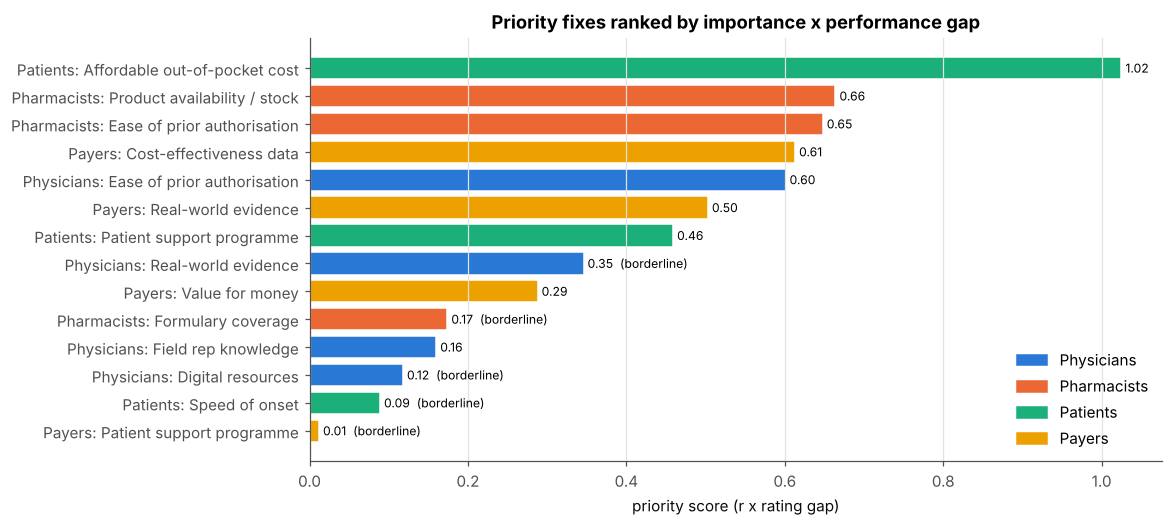

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
lbl = fixes["group"] + ": " + fixes["driver_label"]
colors = [PALETTE[GROUPS.index(g)] for g in fixes["group"]]
ax.barh(lbl, fixes["priority_score"], color=colors, edgecolor="white")
ax.invert_yaxis()
for y, (v, conf) in enumerate(zip(fixes["priority_score"], fixes["confidence"])):
    ax.text(v + 0.005, y, f"{v:.2f}" + ("  (borderline)" if conf != "stable" else ""), va="center", fontsize=8)
ax.set(title="Priority fixes ranked by importance x performance gap", xlabel="priority score (r x rating gap)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[i]) for i in range(len(GROUPS))]
ax.legend(handles, GROUPS, loc="lower right")
fig.savefig(FIGS / "04_priority_fixes_ranked.png")
plt.show()

## Hypothesis statements per group

In [5]:
def show(g):
    h = hyp[hyp["group"] == g][["hypothesis_id", "quadrant", "action", "hypothesis", "proposed_test", "confidence"]]
    with pd.option_context("display.max_colwidth", 400):
        display(h.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
show("Physicians")

hypothesis_id,quadrant,action,hypothesis,proposed_test,confidence
PHY-01,Priority fixes,Fix,"If physicians rate ease of prior authorisation higher, their prescribing intent will increase: it is among the strongest correlates of prescribing intent (r = 0.30) but is rated 2.0 points below the group's average attribute rating (4.6 / 10).",Field a targeted intervention on ease of prior authorisation to a test cell of physicians; compare the change in prescribing intent and in the ease of prior authorisation rating against a matched control in the next wave.,stable
PHY-02,Priority fixes,Fix,"If physicians rate real-world evidence higher, their prescribing intent will increase: it is among the strongest correlates of prescribing intent (r = 0.24) but is rated 1.5 points below the group's average attribute rating (5.2 / 10).",Field a targeted intervention on real-world evidence to a test cell of physicians; compare the change in prescribing intent and in the real-world evidence rating against a matched control in the next wave.,borderline (bootstrap)
PHY-03,Priority fixes,Fix,"If physicians rate field rep knowledge higher, their prescribing intent will increase: it is among the strongest correlates of prescribing intent (r = 0.26) but is rated 0.6 points below the group's average attribute rating (6.0 / 10).",Field a targeted intervention on field rep knowledge to a test cell of physicians; compare the change in prescribing intent and in the field rep knowledge rating against a matched control in the next wave.,stable
PHY-04,Priority fixes,Fix,"If physicians rate digital resources higher, their prescribing intent will increase: it is among the strongest correlates of prescribing intent (r = 0.22) but is rated 0.5 points below the group's average attribute rating (6.1 / 10).",Field a targeted intervention on digital resources to a test cell of physicians; compare the change in prescribing intent and in the digital resources rating against a matched control in the next wave.,borderline (bootstrap)
PHY-05,Strengths,Leverage,"Clinical efficacy is a reason physicians support the brand (r = 0.49, rated 7.8 / 10); leading with it in messaging will protect prescribing intent, and any slippage in it would reduce prescribing intent.",Track clinical efficacy as a guardrail metric each wave; A/B test messaging that leads with clinical efficacy.,stable
PHY-06,Strengths,Leverage,"Safety profile is a reason physicians support the brand (r = 0.40, rated 7.5 / 10); leading with it in messaging will protect prescribing intent, and any slippage in it would reduce prescribing intent.",Track safety profile as a guardrail metric each wave; A/B test messaging that leads with safety profile.,stable
PHY-07,Strengths,Leverage,"Guideline endorsement is a reason physicians support the brand (r = 0.33, rated 7.4 / 10); leading with it in messaging will protect prescribing intent, and any slippage in it would reduce prescribing intent.",Track guideline endorsement as a guardrail metric each wave; A/B test messaging that leads with guideline endorsement.,stable
PHY-08,Maintain,Hold,"Company reputation is rated well by physicians (7.4 / 10) but is only weakly linked to prescribing intent (r = 0.13); holding investment flat, or reallocating some of it, will not reduce prescribing intent.",Reallocate a share of company reputation spend to a priority fix and confirm prescribing intent does not fall.,stable
PHY-09,Maintain,Hold,"Affordable out-of-pocket cost is rated well by physicians (7.3 / 10) but is only weakly linked to prescribing intent (r = 0.11); holding investment flat, or reallocating some of it, will not reduce prescribing intent.",Reallocate a share of affordable out-of-pocket cost spend to a priority fix and confirm prescribing intent does not fall.,stable
PHY-10,Low priority,Monitor,Product availability / stock has weak links to prescribing intent among physicians (r = 0.14); improving it is unlikely to move prescribing intent in the near term.,Monitor o

In [6]:
show("Pharmacists")

hypothesis_id,quadrant,action,hypothesis,proposed_test,confidence
PHA-01,Priority fixes,Fix,"If pharmacists rate product availability / stock higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.41) but is rated 1.6 points below the group's average attribute rating (4.6 / 10).",Field a targeted intervention on product availability / stock to a test cell of pharmacists; compare the change in likelihood to recommend and in the product availability / stock rating against a matched control in the next wave.,stable
PHA-02,Priority fixes,Fix,"If pharmacists rate ease of prior authorisation higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.38) but is rated 1.7 points below the group's average attribute rating (4.6 / 10).",Field a targeted intervention on ease of prior authorisation to a test cell of pharmacists; compare the change in likelihood to recommend and in the ease of prior authorisation rating against a matched control in the next wave.,stable
PHA-03,Priority fixes,Fix,"If pharmacists rate formulary coverage higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.26) but is rated 0.7 points below the group's average attribute rating (5.6 / 10).",Field a targeted intervention on formulary coverage to a test cell of pharmacists; compare the change in likelihood to recommend and in the formulary coverage rating against a matched control in the next wave.,borderline (bootstrap)
PHA-04,Strengths,Leverage,"Low drug-interaction risk is a reason pharmacists support the brand (r = 0.43, rated 7.3 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track low drug-interaction risk as a guardrail metric each wave; A/B test messaging that leads with low drug-interaction risk.,stable
PHA-05,Strengths,Leverage,"Medical information responsiveness is a reason pharmacists support the brand (r = 0.24, rated 7.1 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track medical information responsiveness as a guardrail metric each wave; A/B test messaging that leads with medical information responsiveness.,borderline (bootstrap)
PHA-06,Strengths,Leverage,"Digital resources is a reason pharmacists support the brand (r = 0.21, rated 6.8 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track digital resources as a guardrail metric each wave; A/B test messaging that leads with digital resources.,borderline (bootstrap)
PHA-07,Maintain,Hold,"Company reputation is rated well by pharmacists (7.2 / 10) but is only weakly linked to likelihood to recommend (r = 0.10); holding investment flat, or reallocating some of it, will not reduce likelihood to recommend.",Reallocate a share of company reputation spend to a priority fix and confirm likelihood to recommend does not fall.,stable
PHA-08,Maintain,Hold,"Field rep knowledge is rated well by pharmacists (6.9 / 10) but is only weakly linked to likelihood to recommend (r = 0.18); holding investment flat, or reallocating some of it, will not reduce likelihood to recommend.",Reallocate a share of field rep knowledge spend to a priority fix and confirm likelihood to recommend does not fall.,borderline (bootstrap)
PHA-09,Low priority,Monitor,Dosing convenience has weak links to likelihood to recommend among pharmacists (r = 0.12); improving it is unlikely to move likelihood to recommend in the near term.,Monitor only; revisit if its correlation with likelihood to recommend rises above the threshold in a later wave.,stable


In [7]:
show("Patients")

hypothesis_id,quadrant,action,hypothesis,proposed_test,confidence
PAT-01,Priority fixes,Fix,"If patients rate affordable out-of-pocket cost higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.47) but is rated 2.2 points below the group's average attribute rating (4.3 / 10).",Field a targeted intervention on affordable out-of-pocket cost to a test cell of patients; compare the change in likelihood to recommend and in the affordable out-of-pocket cost rating against a matched control in the next wave.,stable
PAT-02,Priority fixes,Fix,"If patients rate patient support programme higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.35) but is rated 1.3 points below the group's average attribute rating (5.2 / 10).",Field a targeted intervention on patient support programme to a test cell of patients; compare the change in likelihood to recommend and in the patient support programme rating against a matched control in the next wave.,stable
PAT-03,Priority fixes,Fix,"If patients rate speed of onset higher, their likelihood to recommend will increase: it is among the strongest correlates of likelihood to recommend (r = 0.23) but is rated 0.4 points below the group's average attribute rating (6.1 / 10).",Field a targeted intervention on speed of onset to a test cell of patients; compare the change in likelihood to recommend and in the speed of onset rating against a matched control in the next wave.,borderline (bootstrap)
PAT-04,Strengths,Leverage,"Tolerability / side effects is a reason patients support the brand (r = 0.37, rated 7.1 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track tolerability / side effects as a guardrail metric each wave; A/B test messaging that leads with tolerability / side effects.,stable
PAT-05,Strengths,Leverage,"Dosing convenience is a reason patients support the brand (r = 0.35, rated 7.5 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track dosing convenience as a guardrail metric each wave; A/B test messaging that leads with dosing convenience.,stable
PAT-06,Strengths,Leverage,"Ease of administration is a reason patients support the brand (r = 0.25, rated 7.4 / 10); leading with it in messaging will protect likelihood to recommend, and any slippage in it would reduce likelihood to recommend.",Track ease of administration as a guardrail metric each wave; A/B test messaging that leads with ease of administration.,stable
PAT-07,Maintain,Hold,"Educational materials is rated well by patients (7.3 / 10) but is only weakly linked to likelihood to recommend (r = 0.14); holding investment flat, or reallocating some of it, will not reduce likelihood to recommend.",Reallocate a share of educational materials spend to a priority fix and confirm likelihood to recommend does not fall.,stable
PAT-08,Maintain,Hold,"Digital resources is rated well by patients (7.0 / 10) but is only weakly linked to likelihood to recommend (r = 0.10); holding investment flat, or reallocating some of it, will not reduce likelihood to recommend.",Reallocate a share of digital resources spend to a priority fix and confirm likelihood to recommend does not fall.,stable
PAT-09,Low priority,Monitor,Adherence tools and reminders has weak links to likelihood to recommend among patients (r = 0.18); improving it is unlikely to move likelihood to recommend in the near term.,Monitor only; revisit if its correlation with likelihood to recommend rises above the threshold in a later wave.,borderline (bootstrap)


In [8]:
show("Payers")

hypothesis_id,quadrant,action,hypothesis,proposed_test,confidence
PAY-01,Priority fixes,Fix,"If payers rate cost-effectiveness data higher, their likelihood to grant preferred formulary status will increase: it is among the strongest correlates of likelihood to grant preferred formulary status (r = 0.43) but is rated 1.4 points below the group's average attribute rating (4.6 / 10).",Field a targeted intervention on cost-effectiveness data to a test cell of payers; compare the change in likelihood to grant preferred formulary status and in the cost-effectiveness data rating against a matched control in the next wave.,stable
PAY-02,Priority fixes,Fix,"If payers rate real-world evidence higher, their likelihood to grant preferred formulary status will increase: it is among the strongest correlates of likelihood to grant preferred formulary status (r = 0.39) but is rated 1.3 points below the group's average attribute rating (4.7 / 10).",Field a targeted intervention on real-world evidence to a test cell of payers; compare the change in likelihood to grant preferred formulary status and in the real-world evidence rating against a matched control in the next wave.,stable
PAY-03,Priority fixes,Fix,"If payers rate value for money higher, their likelihood to grant preferred formulary status will increase: it is among the strongest correlates of likelihood to grant preferred formulary status (r = 0.33) but is rated 0.9 points below the group's average attribute rating (5.2 / 10).",Field a targeted intervention on value for money to a test cell of payers; compare the change in likelihood to grant preferred formulary status and in the value for money rating against a matched control in the next wave.,stable
PAY-04,Priority fixes,Fix,"If payers rate patient support programme higher, their likelihood to grant preferred formulary status will increase: it is among the strongest correlates of likelihood to grant preferred formulary status (r = 0.23) but is rated 0.1 points below the group's average attribute rating (6.0 / 10).",Field a targeted intervention on patient support programme to a test cell of payers; compare the change in likelihood to grant preferred formulary status and in the patient support programme rating against a matched control in the next wave.,borderline (bootstrap)
PAY-05,Strengths,Leverage,"Clinical efficacy is a reason payers support the brand (r = 0.37, rated 7.5 / 10); leading with it in messaging will protect likelihood to grant preferred formulary status, and any slippage in it would reduce likelihood to grant preferred formulary status.",Track clinical efficacy as a guardrail metric each wave; A/B test messaging that leads with clinical efficacy.,stable
PAY-06,Strengths,Leverage,"Durability of response is a reason payers support the brand (r = 0.36, rated 6.8 / 10); leading with it in messaging will protect likelihood to grant preferred formulary status, and any slippage in it would reduce likelihood to grant preferred formulary status.",Track durability of response as a guardrail metric each wave; A/B test messaging that leads with durability of response.,stable
PAY-07,Maintain,Hold,"Guideline endorsement is rated well by payers (6.8 / 10) but is only weakly linked to likelihood to grant preferred formulary status (r = 0.07); holding investment flat, or reallocating some of it, will not reduce likelihood to grant preferred formulary status.",Reallocate a share of guideline endorsement spend to a priority fix and confirm likelihood to grant preferred formulary status does not fall.,stable
PAY-08,Maintain,Hold,"Company reputation is rated well by payers (6.7 / 10) but is only weakly linked to likelihood to grant preferred formulary status (r = -0.08); holding investment flat, or reallocating some of it, will not reduce likelihood to grant preferred formulary status.",Reallocate a share of company reputation spend to a priority fix and confirm likelihood to grant preferred formulary status does not fall.,stable
PAY-

## Cross-stakeholder hypotheses

In [9]:
cross = cross_group_hypotheses(results, ATTRIBUTES)
with pd.option_context("display.max_colwidth", 400):
    display(cross[["driver_label", "quadrant", "groups", "hypothesis"]].style.hide(axis="index")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

driver_label,quadrant,groups,hypothesis
Patient support programme,Priority fixes,"Patients, Payers","Patient support programme is a shared fix across Patients, Payers (Patients r = 0.35, Payers r = 0.23); a single cross-functional initiative on it will lift the outcome in all of these groups at lower cost than separate group-level programmes."
Ease of prior authorisation,Priority fixes,"Physicians, Pharmacists","Ease of prior authorisation is a shared fix across Physicians, Pharmacists (Physicians r = 0.30, Pharmacists r = 0.38); a single cross-functional initiative on it will lift the outcome in all of these groups at lower cost than separate group-level programmes."
Real-world evidence,Priority fixes,"Physicians, Payers","Real-world evidence is a shared fix across Physicians, Payers (Physicians r = 0.24, Payers r = 0.39); a single cross-functional initiative on it will lift the outcome in all of these groups at lower cost than separate group-level programmes."
Clinical efficacy,Strengths,"Physicians, Payers","Clinical efficacy is a shared strength across Physicians, Payers (Physicians r = 0.49, Payers r = 0.37); leading with it in common core messaging will sustain the outcome in all of these groups, and a drop in its rating would hit them together."


## Export

In [10]:
cols = ["hypothesis_id", "group", "quadrant", "action", "driver", "driver_label", "importance_r", "performance",
        "priority_score", "rank_rw", "confidence", "hypothesis", "proposed_test"]
hyp[cols].to_csv(PROCESSED / "hypotheses_by_group.csv", index=False)
cross.to_csv(PROCESSED / "hypotheses_cross_group.csv", index=False)

top = (hyp[hyp["quadrant"] == "Priority fixes"].sort_values("priority_score", ascending=False)
       .groupby("group", sort=False).head(1).set_index("group").loc[GROUPS])
headline = pd.DataFrame({
    "top_priority_fix": top["driver_label"],
    "r": top["importance_r"], "rating": top["performance"],
    "n_strengths": hyp[hyp["quadrant"] == "Strengths"].groupby("group").size().reindex(GROUPS),
    "n_priority_fixes": hyp[hyp["quadrant"] == "Priority fixes"].groupby("group").size().reindex(GROUPS),
})
headline

,top_priority_fix,r,rating,n_strengths,n_priority_fixes
group,,,,,
Physicians,Ease of prior authorisation,0.296,4.590,3,4
Pharmacists,Product availability / stock,0.408,4.620,3,3
Patients,Affordable out-of-pocket cost,0.465,4.330,3,3
Payers,Cost-effectiveness data,0.431,4.610,2,4


## Findings

* The framework produced **37 group-level hypotheses** (14 priority fixes, 11 strengths, 8 maintain, 4 low-priority
  monitor items) and **4 cross-stakeholder hypotheses**, each with evidence, a proposed test and an action.
* Top priority fixes by importance x rating gap: patients' affordable out-of-pocket cost (score 1.03), pharmacists'
  product availability (0.66) and ease of prior authorisation (0.65), payers' cost-effectiveness data (0.61) and
  physicians' ease of prior authorisation (0.60). All five are stable in the bootstrap.
* Five of the 14 priority fixes are flagged borderline (physicians' real-world evidence and digital resources,
  pharmacists' formulary coverage, patients' speed of onset, payers' patient support programme) and should be
  re-tested in the next wave before investment.
* Cross-stakeholder hypotheses: ease of prior authorisation (Physicians and Pharmacists), real-world evidence
  (Physicians and Payers) and patient support programme (Patients and Payers) are shared fixes; clinical efficacy is a
  shared strength for Physicians and Payers.
* Exports: `data/processed/hypotheses_by_group.csv` and `data/processed/hypotheses_cross_group.csv`.